#  Кластеризация активности пользователей на основе данных носимых устройств

Компания собирает данные с носимых устройств пользователей (фитнес-браслетов, датчиков движения, пульсометров) для анализа физической активности.

На основе сигналов с трёх инерциальных измерительных модулей (IMU) и пульсометра необходимо сгруппировать наблюдения по типу активности пользователя (например, ходьба, бег, сон, отдых и другие).

## Подготовка

In [47]:
# импорт необходимых библиотек
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, RobustScaler   
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.cluster import (
    KMeans,
    DBSCAN,
    AgglomerativeClustering
)

from sklearn.metrics import silhouette_score


RANDOM_STATE = 42

In [8]:
# загрузка данных
data = pd.read_csv('datasets/Physical_Activity_Monitoring_unlabeled.csv')

data.head()

,timestamp,handTemperature,handAcc16_1,handAcc16_2,handAcc16_3,handAcc6_1,handAcc6_2,handAcc6_3,handGyro1,handGyro2,...,ankleGyro2,ankleGyro3,ankleMagne1,ankleMagne2,ankleMagne3,ankleOrientation1,ankleOrientation2,ankleOrientation3,ankleOrientation4,subject_id
0,252.75,34.8750,0.902847,7.45872,6.032490,1.006100,7.44575,6.303650,-0.021952,0.004114,...,-0.025606,0.030239,-14.5447,27.3336,-5.76620,0.206416,0.348212,0.763201,-0.503652,5
1,3652.45,29.7500,-4.069330,3.76168,8.279720,-5.972500,3.22273,6.908970,0.116054,-0.375968,...,-0.670163,1.786200,-32.8257,-15.7719,-1.31395,0.578332,-0.566734,0.405888,-0.423791,2
2,504.76,34.3750,-2.007540,-9.60180,0.773674,-1.803500,-9.58937,1.073680,0.020131,0.042189,...,-0.009741,-0.006579,-18.8171,16.3089,25.29280,0.139776,0.676586,0.393796,0.606316,8
3,2801.61,31.9375,-13.262200,5.85443,0.899334,-13.611500,5.91511,0.840377,1.715630,-0.050492,...,-0.163470,-3.495570,-26.7418,34.3566,21.32740,0.416303,0.783387,0.306464,0.345075,2
4,441.01,33.5000,-0.013940,8.66540,4.398210,0.144153,8.56816,4.822200,-0.006938,-0.007383,...,-0.028172,-0.003737,-17.7798,-3.9981,10.99500,0.171133,-0.748343,0.252988,-0.588807,6


Данные успешно загружены и готовы к предварительному анализу.

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 534601 entries, 0 to 534600
Data columns (total 53 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   timestamp          534601 non-null  float64
 1   handTemperature    530560 non-null  float64
 2   handAcc16_1        530560 non-null  float64
 3   handAcc16_2        530560 non-null  float64
 4   handAcc16_3        530560 non-null  float64
 5   handAcc6_1         530560 non-null  float64
 6   handAcc6_2         530560 non-null  float64
 7   handAcc6_3         530560 non-null  float64
 8   handGyro1          530560 non-null  float64
 9   handGyro2          530560 non-null  float64
 10  handGyro3          530560 non-null  float64
 11  handMagne1         530560 non-null  float64
 12  handMagne2         530560 non-null  float64
 13  handMagne3         530560 non-null  float64
 14  handOrientation1   530560 non-null  float64
 15  handOrientation2   530560 non-null  float64
 16  ha

In [10]:
data.describe()

,timestamp,handTemperature,handAcc16_1,handAcc16_2,handAcc16_3,handAcc6_1,handAcc6_2,handAcc6_3,handGyro1,handGyro2,...,ankleGyro2,ankleGyro3,ankleMagne1,ankleMagne2,ankleMagne3,ankleOrientation1,ankleOrientation2,ankleOrientation3,ankleOrientation4,subject_id
count,534601.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,...,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,534601.000000
mean,1593.538159,32.451221,-4.435286,3.241949,4.079375,-4.375896,3.218250,4.262513,-0.008852,0.028801,...,-0.031911,0.002304,-28.756284,2.115624,14.723345,0.360159,-0.091093,0.303517,-0.173845,4.558615
std,1243.906483,1.754847,7.062004,7.224031,3.831257,7.068961,6.864782,3.822053,1.160112,0.926832,...,0.618840,2.036102,19.303887,22.253170,17.907491,0.301254,0.559400,0.344271,0.466304,2.318076
min,37.660000,27.500000,-114.755000,-82.550900,-73.949700,-61.214700,-61.824200,-61.577100,-19.690500,-7.609010,...,-7.701040,-14.019600,-172.865000,-136.951000,-102.716000,0.000003,-0.954848,-0.876838,-0.997040,1.000000
25%,475.500000,31.312500,-9.076360,0.682775,1.588777,-8.981072,0.687587,1.780160,-0.153182,-0.083315,...,-0.049003,-0.221911,-39.689950,-10.960850,2.252230,0.145023,-0.676392,0.006839,-0.580040,2.000000
50%,827.610000,32.875000,-5.465610,3.089205,4.157125,-5.434845,3.127145,4.413625,-0.004439,0.004013,...,-0.004481,0.000354,-26.285600,-0.014372,16.599500,0.240996,0.000000,0.322698,-0.281681,5.000000
75%,2876.990000,33.812500,0.383679,5.559742,6.864212,0.424770,5.592180,7.148178,0.130310,0.094342,...,0.048972,0.032649,-14.549500,19.245900,25.947100,0.501671,0.410052,0.594198,0.252247,7.000000
max,4007.730000,35.250000,60.912600,155.532000,78.480100,34.159400,62.259800,60.843700,22.960000,11.862600,...,6.002540,14.482700,41.764800,92.867000,122.521000,1.000000,0.959538,0.920506,0.996105,8.000000


Все признаки имеют числовой тип (float64), что соответствует данным сенсорных измерений и не требует преобразования.

## Первичный анализ данных

### Общая характеристика
- **Объем данных**: 534 601 запись, 53 признака
- **Устройства**: 3 носимых датчика (hand, chest, ankle)
- **Типы измерений**: акселерометр (Acc), гироскоп (Gyro), магнитометр (Magne), ориентация (Orientation), температура (Temp)
- **Испытуемые**: 8 человек (subject_id 1-8)

In [11]:
# Выявление полей с пропусками
missing_cols = data.columns[data.isnull().any()].tolist()
print(f"Поля с пропусками ({len(missing_cols)}): {missing_cols}")

# Поля, требующие преобразования
for col in missing_cols:
    missing_pct = data[col].isnull().sum() / len(data) * 100
    print(f"{col}: пропущено {missing_pct:.2f}%")

Поля с пропусками (51): ['handTemperature', 'handAcc16_1', 'handAcc16_2', 'handAcc16_3', 'handAcc6_1', 'handAcc6_2', 'handAcc6_3', 'handGyro1', 'handGyro2', 'handGyro3', 'handMagne1', 'handMagne2', 'handMagne3', 'handOrientation1', 'handOrientation2', 'handOrientation3', 'handOrientation4', 'chestTemperature', 'chestAcc16_1', 'chestAcc16_2', 'chestAcc16_3', 'chestAcc6_1', 'chestAcc6_2', 'chestAcc6_3', 'chestGyro1', 'chestGyro2', 'chestGyro3', 'chestMagne1', 'chestMagne2', 'chestMagne3', 'chestOrientation1', 'chestOrientation2', 'chestOrientation3', 'chestOrientation4', 'ankleTemperature', 'ankleAcc16_1', 'ankleAcc16_2', 'ankleAcc16_3', 'ankleAcc6_1', 'ankleAcc6_2', 'ankleAcc6_3', 'ankleGyro1', 'ankleGyro2', 'ankleGyro3', 'ankleMagne1', 'ankleMagne2', 'ankleMagne3', 'ankleOrientation1', 'ankleOrientation2', 'ankleOrientation3', 'ankleOrientation4']
handTemperature: пропущено 0.76%
handAcc16_1: пропущено 0.76%
handAcc16_2: пропущено 0.76%
handAcc16_3: пропущено 0.76%
handAcc6_1: пропущен

В связи с наличием около 1% пропусков в 51 признаке временных рядов применена двусторонняя фиксация пропусков (forward fill + backward fill). Метод обеспечивает сохранение всех записей и непрерывности сигналов без потери информации о последовательности измерений.

In [12]:

data_filled = data.ffill().bfill()
data_filled.isnull().sum().sum()

np.int64(0)

In [13]:
duplicates = data.duplicated().sum()
f'Количество дубликатов: {duplicates}'

'Количество дубликатов: 0'

Полностью дублирующиеся наблюдения отсутствуют, дополнительная обработка не требуется.

In [14]:
data['subject_id'].value_counts(normalize=True)

subject_id
5    0.143645
8    0.136638
6    0.131388
1    0.130718
2    0.128582
4    0.119229
7    0.116189
3    0.093610
Name: proportion, dtype: float64

Распределение наблюдений между пользователями не демонстрирует критического дисбаланса.

In [15]:
sensor_cols = [col for col in data_filled.columns if col not in ['timestamp', 'subject_id']]
data_sensor = data_filled[sensor_cols].copy()

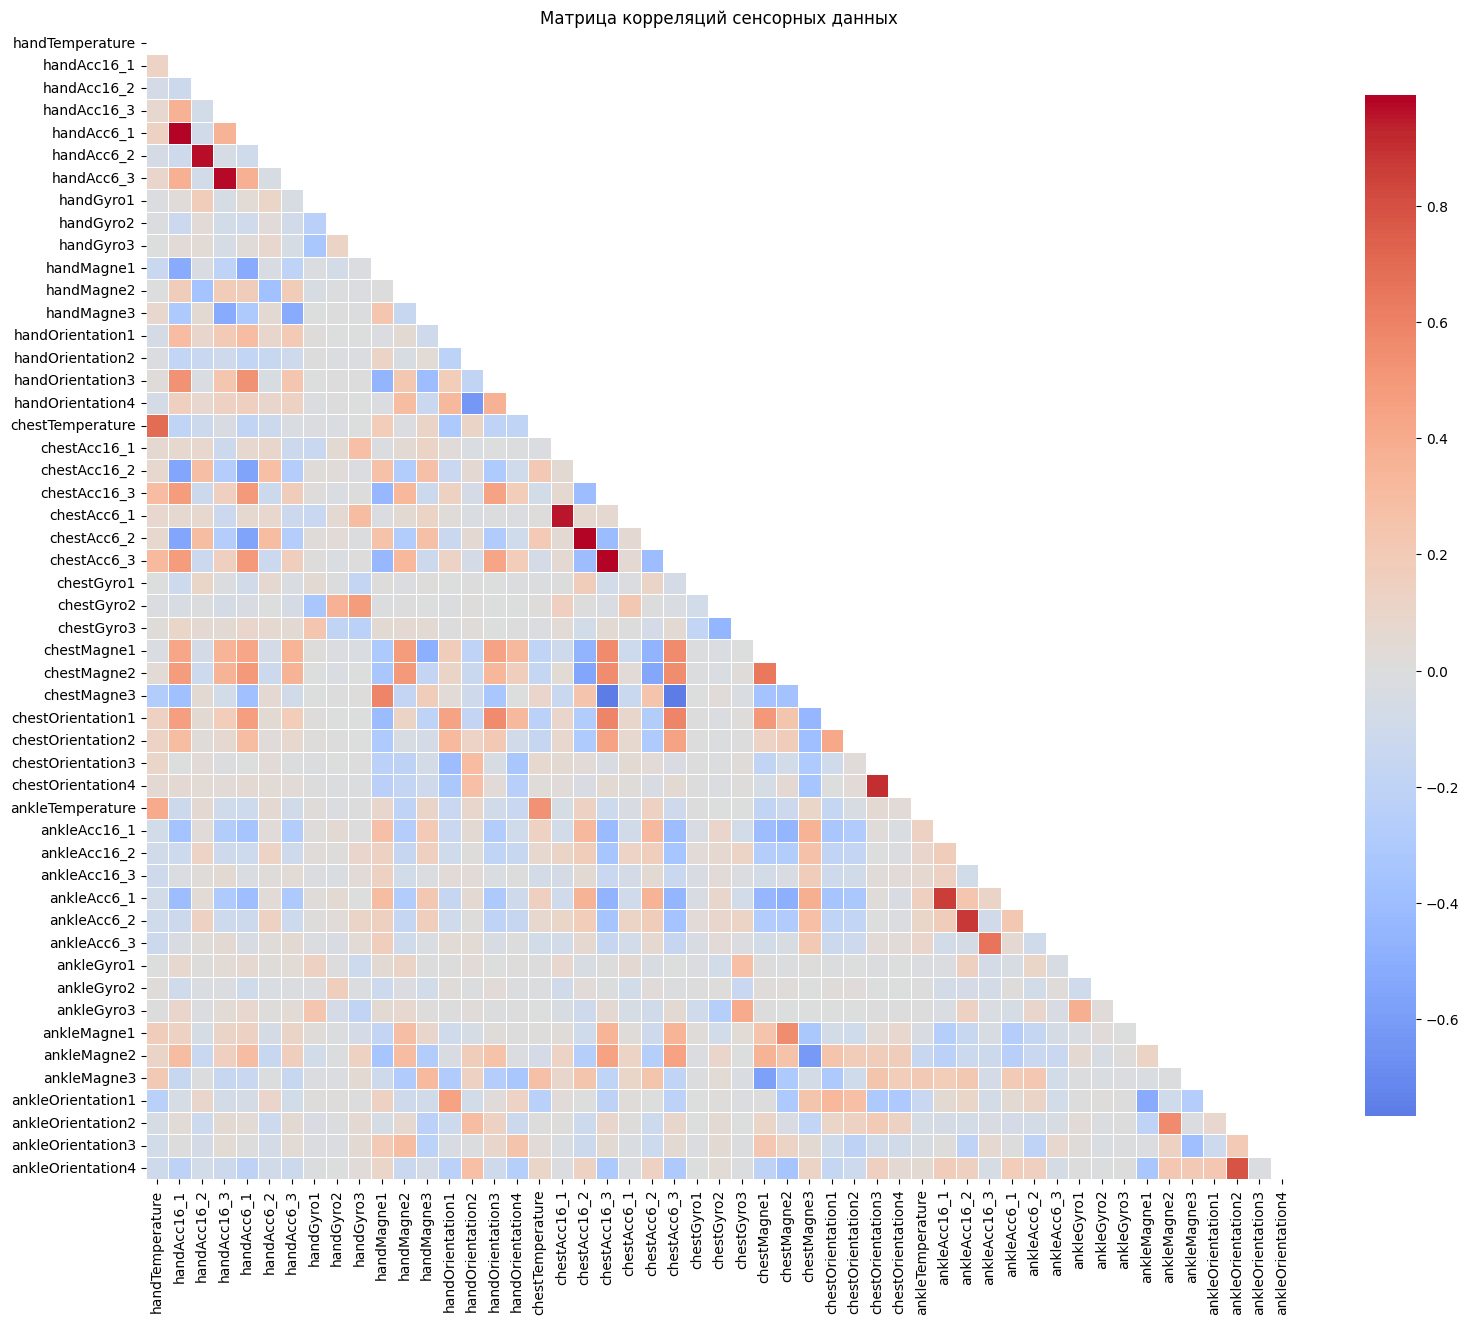

СТАТИСТИКА КОРРЕЛЯЦИЙ
Сильные положительные (>0.7):     10 пар
Сильные отрицательные (<-0.7):     2 пар
Средние положительные (0.3-0.7):   78 пар
Средние отрицательные (-0.7..-0.3):   81 пар
Слабые (|r|<0.3):               1104 пар
------------------------------------------------------------
ВСЕГО: 1275 пар


In [16]:
# Вычисляем корреляционную матрицу
corr_matrix = data_sensor.corr()

plt.figure(figsize=(16, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Матрица корреляций сенсорных данных')
plt.tight_layout()
plt.show()

corr_df = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_df.columns = ['feature_1', 'feature_2', 'correlation']

# Статистика
strong_pos = corr_df[corr_df['correlation'] > 0.7]
strong_neg = corr_df[corr_df['correlation'] < -0.7]
medium_pos = corr_df[(corr_df['correlation'] > 0.3) & (corr_df['correlation'] <= 0.7)]
medium_neg = corr_df[(corr_df['correlation'] < -0.3) & (corr_df['correlation'] >= -0.7)]
weak_pos = corr_df[(corr_df['correlation'] > 0) & (corr_df['correlation'] <= 0.3)]
weak_neg = corr_df[(corr_df['correlation'] < 0) & (corr_df['correlation'] >= -0.3)]

print("="*60)
print("СТАТИСТИКА КОРРЕЛЯЦИЙ")
print("="*60)
print(f"Сильные положительные (>0.7):   {len(strong_pos):4} пар")
print(f"Сильные отрицательные (<-0.7):  {len(strong_neg):4} пар")
print(f"Средние положительные (0.3-0.7): {len(medium_pos):4} пар")
print(f"Средние отрицательные (-0.7..-0.3): {len(medium_neg):4} пар")
print(f"Слабые (|r|<0.3):               {len(weak_pos) + len(weak_neg):4} пар")
print("-"*60)
print(f"ВСЕГО: {len(corr_df)} пар")


### Корреляционный анализ

Матрица корреляций показывает, что большинство связей между признаками слабые (доля сильных корреляций <2%). Однако внутри групп сенсоров одного типа (например, акселерометры hand) наблюдаются заметные зависимости.

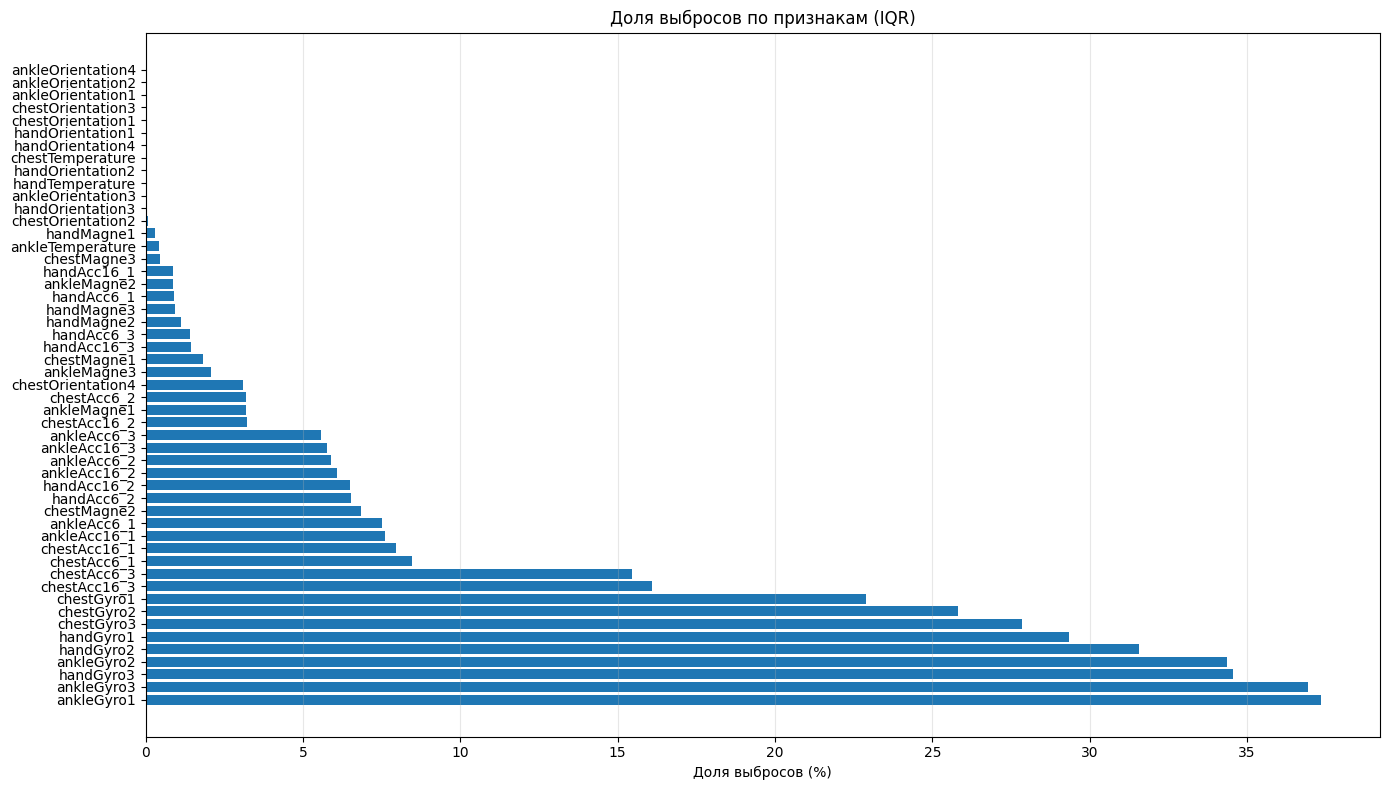

Признаков с выбросами >5%: 22


In [17]:
outliers_share = {}

for col in sensor_cols:
    Q1 = data_sensor[col].quantile(0.25)
    Q3 = data_sensor[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = (
        (data_sensor[col] < Q1 - 1.5 * IQR) |
        (data_sensor[col] > Q3 + 1.5 * IQR)
    )

    outliers_share[col] = outliers.mean() * 100

outliers_df = (
    pd.DataFrame({'outliers_pct': outliers_share})
    .sort_values('outliers_pct', ascending=False)
)

plt.figure(figsize=(14, 8))
plt.barh(outliers_df.index,
         outliers_df['outliers_pct'])

plt.xlabel('Доля выбросов (%)')
plt.title('Доля выбросов по признакам (IQR)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print(
    'Признаков с выбросами >5%:',
    (outliers_df['outliers_pct'] > 5).sum()
)

### Анализ выбросов

Для оценки наличия экстремальных значений использован метод межквартильного размаха (IQR).

Анализ показал, что у 22 признаков более 5% наблюдений выходят за границы межквартильного интервала. Для сенсорных данных это ожидаемо: резкие движения, смена активности, ускорения и повороты тела могут формировать значения, интерпретируемые как выбросы.

Удаление или агрессивная корректировка таких наблюдений может привести к потере значимой информации о поведении пользователя. Обработаем их далее.

### Агрегация данных по временным окнам

Исходные данные представлены последовательностью сенсорных измерений. Кластеризация отдельных измерений чувствительна к шуму и требует значительных вычислительных ресурсов.

**Влияние агрегации на шум:**

- Сглаживает кратковременные выбросы за счет вычисления средних и медианных значений
- Уменьшает влияние случайных флуктуаций через статистические характеристики окна
- Не удаляет систематический шум полностью, но снижает его воздействие на результаты кластеризации

Параметры окон: Размер окна = 50 измерений. Перекрытие окон (step=25) позволяет уменьшить потерю информации на границах активности и обеспечивает плавное восстановление кластеров.

**Процесс агрегации:**

Данные преобразуются в перекрывающиеся временные окна, отдельно для каждого пользователя. Для каждого окна вычисляются статистические признаки:
- `mean`, `std` — центральная тенденция и вариабельность
- `min`, `max`, `p25`, `p75` — экстремумы и квартили
- `mean_change`, `total_change` — динамика изменений

**Исключение неинформативных признаков**

Признаки `timestamp` и `subject_id` не отражают физическую активность пользователя:
- `subject_id` может привести к кластеризации по личности, а не по типу активности
- `timestamp` способен вносить временной сдвиг и формировать искусственные зависимости

Для предотвращения кластеризации по идентификатору пользователя и времени записи данные признаки исключаются из анализа.


In [18]:
def aggregate_window(df, window_size=50, step=25):
    sensor_cols = [col for col in df.columns if col not in ['timestamp', 'subject_id']]

    aggregated_features = []
    metadata = []  # теперь храним индексы!

    for subject in df['subject_id'].unique():
        subject_data = df[df['subject_id'] == subject].sort_values('timestamp')
        subject_indices = subject_data.index.tolist()
        subject_sensors = subject_data[sensor_cols].values

        for start in range(0, len(subject_sensors) - window_size + 1, step):
            window = subject_sensors[start:start + window_size]
            window_indices = subject_indices[start:start + window_size]  # индексы записей в окне

            # Вычисляем признаки как раньше
            features = []
            for col_idx in range(window.shape[1]):
                col_data = window[:, col_idx]
                features.extend([
                    np.mean(col_data), np.std(col_data),
                    np.min(col_data), np.max(col_data),
                    np.percentile(col_data, 25), np.percentile(col_data, 75),
                    np.mean(np.abs(np.diff(col_data))),
                    np.sum(np.abs(np.diff(col_data))),
                ])

            aggregated_features.append(features)

            # Сохраняем ВСЕ индексы записей в этом окне
            metadata.append({
                'subject_id': subject,
                'window_indices': window_indices,  # список индексов!
                'window_start': start,
                'window_end': start + window_size
            })

    # Создаем DataFrame признаков
    feature_names = []
    for col in sensor_cols:
        for stat in ['mean', 'std', 'min', 'max', 'p25', 'p75', 'mean_change', 'total_change']:
            feature_names.append(f"{col}_{stat}")

    X_aggregated = pd.DataFrame(aggregated_features, columns=feature_names)
    metadata_df = pd.DataFrame(metadata)

    return X_aggregated, metadata_df

In [20]:
X_agg, metadata = aggregate_window(data_filled, window_size=50, step=25)
print(f"После агрегации: {X_agg.shape} окон наблюдений")

f"После агрегации объем данных составляет { X_agg.shape[0] / data_filled.shape[0]:.1%} от исходного"

После агрегации: (21371, 408) окон наблюдений


'После агрегации объем данных составляет 4.0% от исходного'

In [21]:
# Вычисляем корреляционную матрицу
corr_matrix = X_agg.corr()

corr_df = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_df.columns = ['feature_1', 'feature_2', 'correlation']

# Статистика
strong_pos = corr_df[corr_df['correlation'] > 0.7]
strong_neg = corr_df[corr_df['correlation'] < -0.7]
medium_pos = corr_df[(corr_df['correlation'] > 0.3) & (corr_df['correlation'] <= 0.7)]
medium_neg = corr_df[(corr_df['correlation'] < -0.3) & (corr_df['correlation'] >= -0.7)]
weak_pos = corr_df[(corr_df['correlation'] > 0) & (corr_df['correlation'] <= 0.3)]
weak_neg = corr_df[(corr_df['correlation'] < 0) & (corr_df['correlation'] >= -0.3)]

print(f"Сильные положительные (>0.7):   {len(strong_pos):4} пар")
print(f"Сильные отрицательные (<-0.7):  {len(strong_neg):4} пар")
print(f"Средние положительные (0.3-0.7): {len(medium_pos):4} пар")
print(f"Средние отрицательные (-0.7..-0.3): {len(medium_neg):4} пар")
print(f"Слабые (|r|<0.3):               {len(weak_pos) + len(weak_neg):4} пар")
print("-"*60)
print(f"ВСЕГО: {len(corr_df)} пар")

Сильные положительные (>0.7):   5340 пар
Сильные отрицательные (<-0.7):  1788 пар
Средние положительные (0.3-0.7): 15486 пар
Средние отрицательные (-0.7..-0.3): 11496 пар
Слабые (|r|<0.3):               48918 пар
------------------------------------------------------------
ВСЕГО: 83028 пар


Добавление статистических признаков (min, max, перцентили, изменения) привело к ожидаемой мультиколлинеарности. 

Избыточность признакового пространства требует сокращения размерности. Перед применением PCA проверим масштаб признаков.

In [22]:
X_agg.describe().T[['mean', 'std', 'min', 'max']]


,mean,std,min,max
handTemperature_mean,32.452262,1.740980,27.567500,35.250000
handTemperature_std,0.069515,0.202920,0.000000,2.074294
handTemperature_min,32.266076,1.845071,27.562500,35.250000
handTemperature_max,32.694849,1.720042,27.625000,35.250000
handTemperature_p25,32.443884,1.754637,27.562500,35.250000
...,...,...,...,...
ankleOrientation4_max,-0.045702,0.504027,-0.837539,0.996105
ankleOrientation4_p25,-0.219001,0.445841,-0.972161,0.854450
ankleOrientation4_p75,-0.119854,0.476793,-0.841177,0.940043
ankleOrientation4_mean_change,0.014219,0.026475,0.000000,0.427695


PCA максимизирует дисперсию, поэтому признаки с большим разбросом будут доминировать. В контексте физической активности:

- Высокая вариабельность — информативный признак (разница между ходьбой и бегом, резкие ускорения)
- Перепады значений — характеристика активности, а не шум
- Аномальные выбросы в данных мониторинга маловероятны

Таким образом, **StandardScaler предпочтительнее** — он сохраняет естественную вариативность сигнала и не подавляет информативные перепады. RobustScaler актуален только при явном присутствии аппаратных сбоев или артефактов.

In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_agg)

Для снижения размерности используется PCA с сохранением 90% дисперсии.

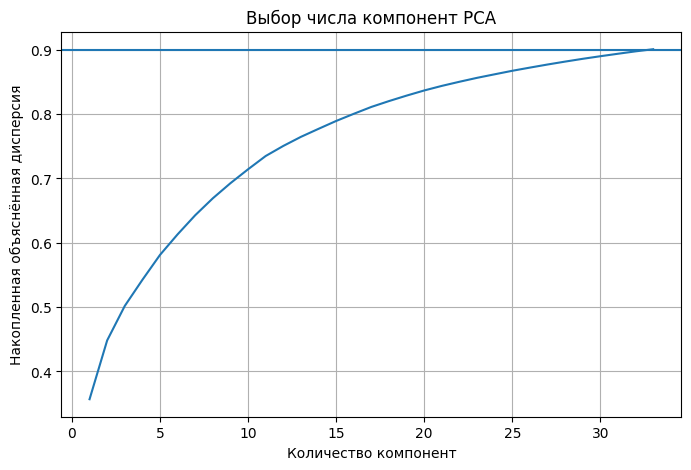

np.int64(33)

In [41]:
pca = PCA(n_components=0.9)
X_pca = pca.fit_transform(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_var)+1), cum_var)
plt.axhline(y=0.9)
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('Выбор числа компонент PCA')
plt.grid(True)
plt.show()

pca.n_components_

Анализ главных компонент показал, что для сохранения 90% дисперсии требуется **33 компоненты**. Это позволило сократить размерность признакового пространства примерно на 38% без существенной потери информации.

### Итоги предварительного анализа

- Датасет содержит 534k наблюдений и 53 признака
- Пропуски (~1%) заполнены методом forward/backward fill
- Дубликаты отсутствуют
- Выбросы присутствуют в значительной части признаков, но сохраняются как часть динамики активности
- Признаков слишком много для прямой кластеризации, поэтому данные агрегированы по временным окнам (размер 50, шаг 25)
- После агрегации объем данных сократился до 21,3k окон (~4% от исходного)
- Признаки имеют различный масштаб, для масштабирования выбран StandardScaler
- Наблюдается мультиколлинеарность между статистическими признаками
- Предварительный анализ PCA показал, что для сохранения 90% дисперсии требуется 33 компоненты

**Вывод:** данные готовы к применению алгоритмов кластеризации.

# Обучение моделей

Для решения задачи кластеризации физической активности исследованы **три алгоритма** с различными подходами к группировке данных: **KMeans** (центроидный), **Agglomerative** (иерархический) и **DBSCAN** (плотностной).

**Метрика оценки:** Для сравнения качества кластеризации используется **silhouette score**. Метрика измеряет, насколько объект похож на свой кластер по сравнению с соседними (диапазон от -1 до 1, чем выше — тем лучше).

**Выбор лучшей модели** осуществляется по совокупности критериев:
- Максимальный silhouette score — количественная мера разделимости кластеров
- Реалистичное количество кластеров — ожидается 5–7 типов физической активности
- Сбалансированность распределения — отсутствие экстремально малых кластеров (менее 50 записей)

**Вспомогательные методы обоснования:**
- Для KMeans — метод локтя (график инерции) для выбора оптимального `k`
- Для DBSCAN — график k-расстояний для предварительной оценки `eps`
- Для Agglomerative — дендрограмма для визуализации иерархической структуры объединения кластеров

Вспомогательные функции для визуализации:

In [25]:
def plot_clusters_2d(X, labels, title):
    plt.figure(figsize=(6, 5))

    scatter = plt.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap='tab10',
        s=8,
        alpha=0.6
    )

    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.grid(alpha=0.3)

    plt.colorbar(scatter, label='Cluster')
    plt.show()

def plot_clusters_distribution(results, model_name='Модель', figsize=(15, 5)):
    n_plots = len(results)
    n_cols = 3
    n_rows = (n_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)

    # Преобразуем axes в плоский список для удобства
    if n_rows == 1 and n_cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for idx, result in enumerate(results):
        # Определяем ключ для количества кластеров
        n_clusters = result.get('k', result.get('n_clusters', '?'))
        distribution = result['distribution']
        silhouette = result['silhouette']

        clusters = sorted(distribution.keys())
        counts = np.array([distribution[c] for c in clusters])

        # Расчет коэффициента вариации
        cv = np.std(counts) / np.mean(counts) if np.mean(counts) > 0 else 0

        # Столбчатая диаграмма
        bars = axes[idx].bar(clusters, counts, color='steelblue', edgecolor='black')
        axes[idx].set_xlabel('Кластер', fontsize=11)
        axes[idx].set_ylabel('Количество записей', fontsize=11)
        axes[idx].set_title(f'k={n_clusters}, silhouette={silhouette:.4f}, CV={cv:.2f}', fontsize=11)
        axes[idx].grid(axis='y', alpha=0.3)

        # Подписи значений на столбцах
        max_count = max(counts) if len(counts) > 0 else 1
        for bar, count in zip(bars, counts):
            axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max_count*0.01,
                           f'{count:,}', ha='center', va='bottom', fontsize=8)

    # Скрываем лишние графики (если есть)
    for idx in range(len(results), len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle(f'Распределение кластеров {model_name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

## KMeans

Методом локтя предварительно определим разумный диапазон числа кластеров для модели k-средних.

k= 2: inertia=5664687
k= 3: inertia=4780641
k= 4: inertia=4138026
k= 5: inertia=3718586
k= 6: inertia=3559603
k= 7: inertia=3425198
k= 8: inertia=3312312
k= 9: inertia=3170038
k=10: inertia=3062387
k=11: inertia=2981166
k=12: inertia=2820786
k=13: inertia=2717941
k=14: inertia=2651888


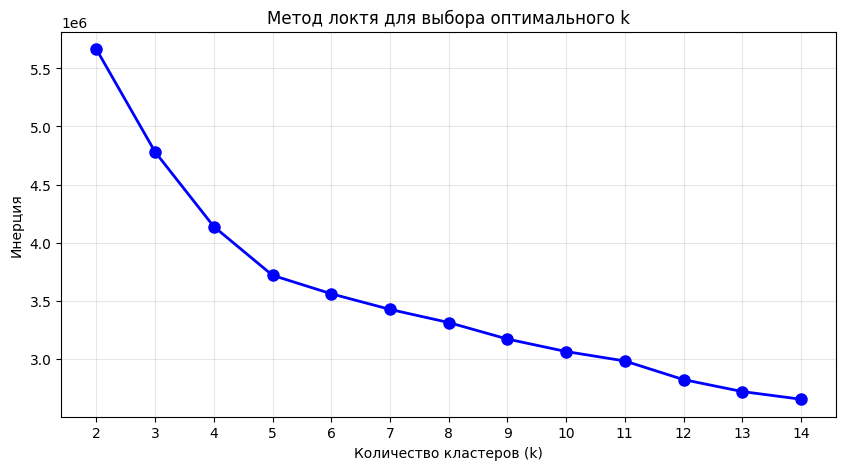

In [26]:
inertias = []
k_range = range(2, 15)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)
    print(f"k={k:2d}: inertia={kmeans.inertia_:.0f}")

plt.figure(figsize=(10, 5))
plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция')
plt.title('Метод локтя для выбора оптимального k')
plt.grid(True, alpha=0.3)
plt.xticks(k_range)
plt.show()

Точка перегиба наблюдается при **k=5**. Дальнейшее увеличение числа кластеров приводит к закону убывающей отдачи — каждый новый кластер дает все меньшее улучшение компактности.

Таким образом, оптимальным диапазоном для кластеризации является **k = 5–6**, что согласуется с ожидаемым количеством типов физической активности (ходьба, бег, сон, отдых, активное движение).

In [27]:
kmeans_results = []

k_values = [4, 5, 6]

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    unique, counts = np.unique(labels, return_counts=True)
    cluster_stats = dict(zip(unique, counts))

    kmeans_results.append({
        'k': k,
        'model': model,
        'labels': labels,
        'silhouette': score,
        'distribution': cluster_stats
    })

    print(
        f'k={k}: '
        f'silhouette={score:.4f}, '
        f'распределение={cluster_stats}'
   )

k=4: silhouette=0.2362, распределение={np.int32(0): np.int64(7497), np.int32(1): np.int64(8575), np.int32(2): np.int64(1796), np.int32(3): np.int64(3503)}
k=5: silhouette=0.2548, распределение={np.int32(0): np.int64(4692), np.int32(1): np.int64(3232), np.int32(2): np.int64(1790), np.int32(3): np.int64(3501), np.int32(4): np.int64(8156)}
k=6: silhouette=0.2163, распределение={np.int32(0): np.int64(3200), np.int32(1): np.int64(3928), np.int32(2): np.int64(4682), np.int32(3): np.int64(3498), np.int32(4): np.int64(4273), np.int32(5): np.int64(1790)}


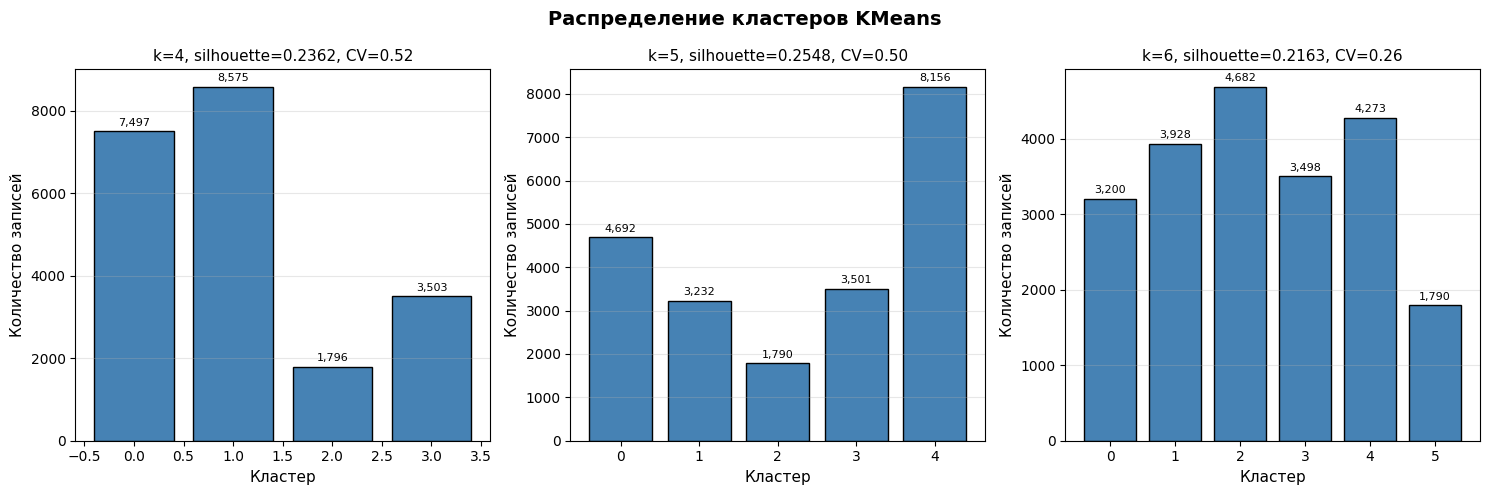

In [28]:
plot_clusters_distribution(kmeans_results, model_name='KMeans')

**Анализ:**

- k=5 показывает максимальный силуэт (0.2548). Распределение приобретает естественную иерархию: крупный кластер (8,156), два средних (4,692 и 3,501) и два компактных (3,232 и 1,790). Такая структура интерпретируется как градиент интенсивности активности — от высокодинамичной к пассивной.
- k=4 и k=6 демонстрируют более низкий силуэт. При k=4 кластеров недостаточно для дифференциации всего спектра активностей. При k=6 наблюдается дробление крупного кластера на два средних без улучшения качества — закон убывающей отдачи.

**Вывод:** оптимальным является k=5.


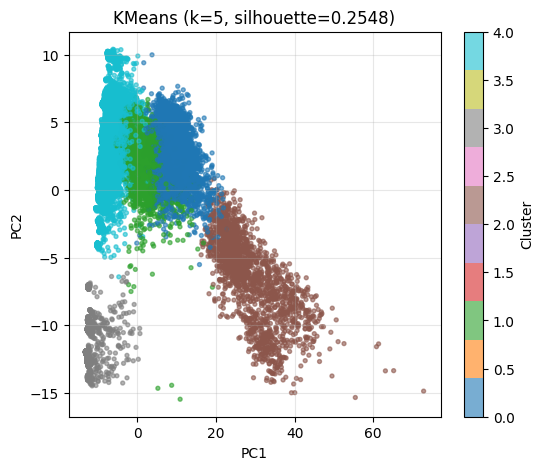

In [29]:
res_i = 1
plot_clusters_2d(
    X=X_pca,
    labels=kmeans_results[res_i]['labels'],  # k=5
    title=f"KMeans (k={kmeans_results[res_i]['k']}, silhouette={kmeans_results[res_i]['silhouette']:.4f})"
)


## DBSCAN
### Подбор параметра `eps`

Для выбора параметра `eps` используем график расстояний до `k`-го ближайшего соседа (`k-distance graph`).

Параметр `min_samples` предварительно зададим равным 10, тогда число соседей для анализа расстояний составит `k = min_samples - 1 = 9`.

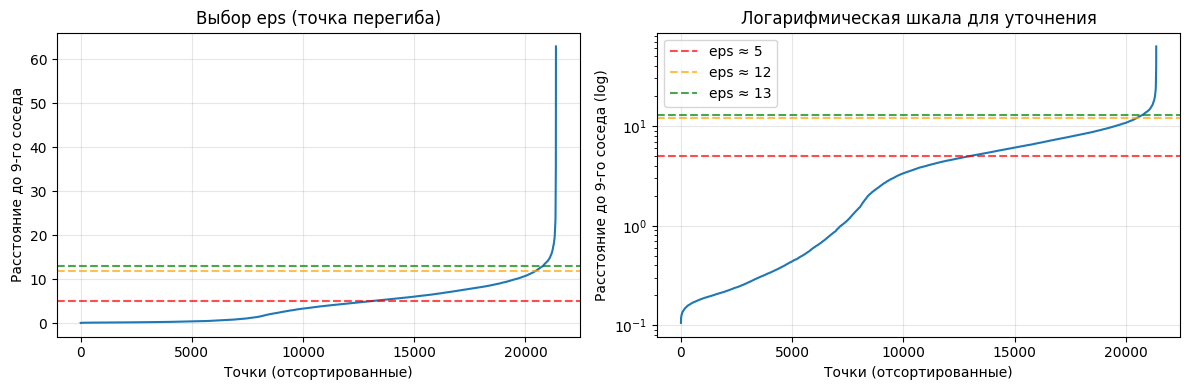

In [44]:
# Параметры
min_samples = 10  # кандидат
k = min_samples - 1  # k = 9

# Вычисляем расстояния
neigh = NearestNeighbors(n_neighbors=k)
neigh.fit(X_pca)
distances, _ = neigh.kneighbors(X_pca)

# Сортируем расстояния до k-го соседа
k_distances = np.sort(distances[:, -1])
eps_vars = [5, 12, 13]
eps_colors =  ['red', 'orange', 'green', 'blue', 'purple']

# Визуализация
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_distances)
plt.xlabel('Точки (отсортированные)')
plt.ylabel(f'Расстояние до {k}-го соседа')
plt.title('Выбор eps (точка перегиба)')
plt.grid(True, alpha=0.3)
for i, eps in enumerate(eps_vars):
    plt.axhline(y=eps, color=eps_colors[i], linestyle='--', alpha=0.7, label=f'eps ≈ {eps}')

plt.subplot(1, 2, 2)
plt.plot(k_distances)
plt.yscale('log')
plt.xlabel('Точки (отсортированные)')
plt.ylabel(f'Расстояние до {k}-го соседа (log)')
plt.title('Логарифмическая шкала для уточнения')
plt.grid(True, alpha=0.3)
for i, eps in enumerate(eps_vars):
    plt.axhline(y=eps, color=eps_colors[i], linestyle='--', alpha=0.7, label=f'eps ≈ {eps}')

plt.legend()
plt.tight_layout()
plt.show()

 Точка перегиба визуально определяется в районе eps ≈ 12.0. Все 3 кандидата будут протестированы при переборе гиперпараметров DBSCAN. Значение eps = 5 дополнительно рассмотрено как более строгий вариант для анализа поведения модели при малом радиусе соседства.

In [45]:
dbscan_results = []

min_samples_values = [10, 15, 30]

for eps in eps_vars:
    for min_samples in min_samples_values:

        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        if n_clusters >= 2:
            mask = labels != -1
            score = silhouette_score(X_pca[mask], labels[mask])

            unique, counts = np.unique(labels[mask], return_counts=True)
            cluster_stats = dict(zip(unique, counts))

            dbscan_results.append({
                'eps': eps,
                'min_samples': min_samples,
                'model': model,
                'labels': labels,
                'silhouette': score,
                'n_clusters': n_clusters,
                'n_noise': n_noise,
                'distribution': cluster_stats
            })

            print(
                f'eps={eps}, '
                f'min_samples={min_samples}: '
                f'clusters={n_clusters}, '
                f'noise={n_noise}, '
                f'silhouette={score:.4f} '
                f'распределение={cluster_stats}'
)

eps=5, min_samples=10: clusters=100, noise=6989, silhouette=0.3928 распределение={np.int64(0): np.int64(26), np.int64(1): np.int64(422), np.int64(2): np.int64(422), np.int64(3): np.int64(3404), np.int64(4): np.int64(52), np.int64(5): np.int64(19), np.int64(6): np.int64(12), np.int64(7): np.int64(14), np.int64(8): np.int64(12), np.int64(9): np.int64(67), np.int64(10): np.int64(24), np.int64(11): np.int64(11), np.int64(12): np.int64(151), np.int64(13): np.int64(9), np.int64(14): np.int64(12), np.int64(15): np.int64(185), np.int64(16): np.int64(297), np.int64(17): np.int64(282), np.int64(18): np.int64(30), np.int64(19): np.int64(26), np.int64(20): np.int64(10), np.int64(21): np.int64(11), np.int64(22): np.int64(399), np.int64(23): np.int64(81), np.int64(24): np.int64(136), np.int64(25): np.int64(32), np.int64(26): np.int64(168), np.int64(27): np.int64(16), np.int64(28): np.int64(20), np.int64(29): np.int64(88), np.int64(30): np.int64(172), np.int64(31): np.int64(13), np.int64(32): np.int6

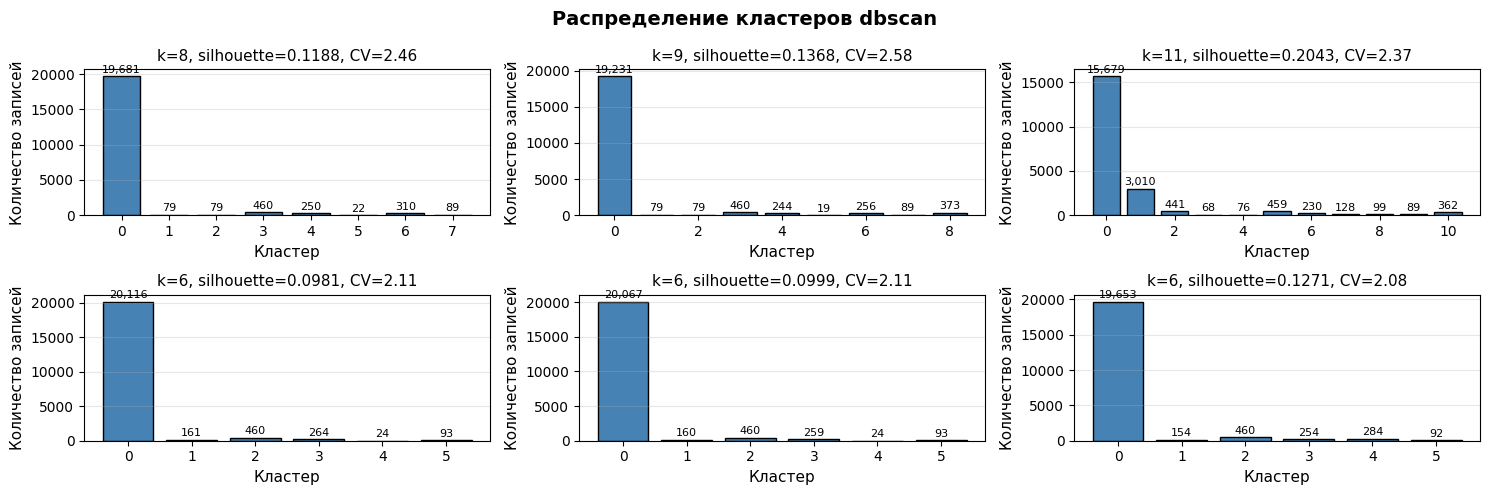

In [32]:
plot_clusters_distribution(dbscan_results[-6:], model_name='dbscan')

**Анализ:**

- eps=5 — данные раздроблены на десятки микро-кластеров. Каждое незначительное изменение в сигнале интерпретируется как отдельный тип активности — содержательно бессмысленно.

- eps=12-13 — почти все данные (95%+) сливаются в один гигантский кластер. Оставшиеся 5% образуют множество карликовых кластеров по 50-500 записей. Сбалансированного распределения достичь не удается.

DBSCAN чувствителен к неоднородной плотности распределения.Физическая активность образует плавные переходы между состояниями — для таких задач плотностные методы не подходят.

**Вывод:** DBSCAN не выделил сбалансированные кластеры в континуальных данных физической активности.

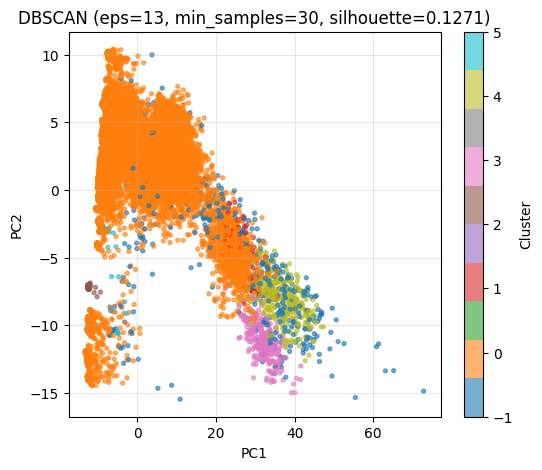

In [ ]:
res_i = -1
plot_clusters_2d(
    X=X_pca,
    labels=dbscan_results[res_i]['labels'],
    title=f"DBSCAN (eps={dbscan_results[res_i]['eps']}, min_samples={dbscan_results[res_i]['min_samples']}, silhouette={dbscan_results[res_i]['silhouette']:.4f})"
)   

## AGGLOMERATIVE

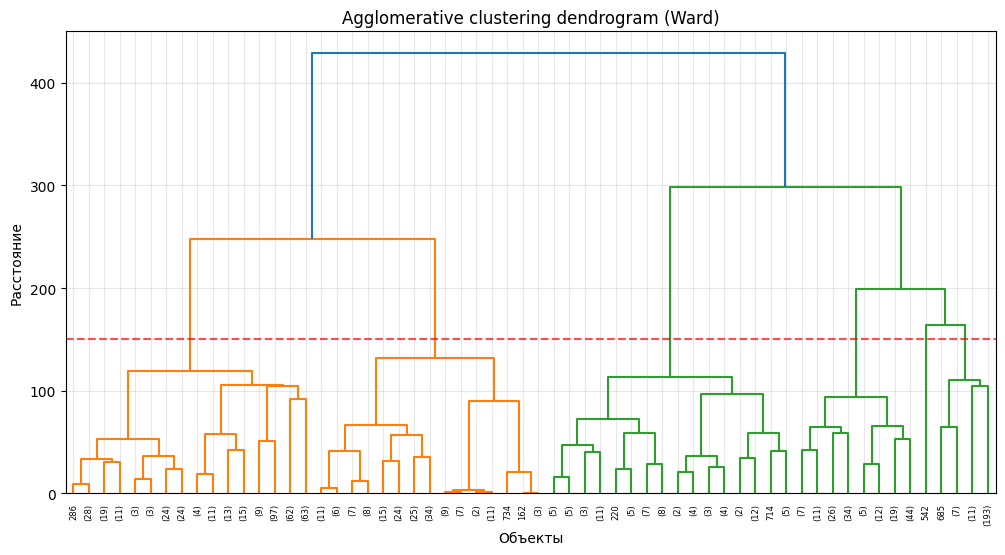

In [48]:
sample_size = 1000

np.random.seed(RANDOM_STATE)
idx = np.random.choice(len(X_pca), sample_size, replace=False)

X_sample = X_pca[idx]

Z = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(Z, truncate_mode='level', p=5)

plt.title('Agglomerative clustering dendrogram (Ward)')
plt.xlabel('Объекты')
plt.ylabel('Расстояние')
plt.grid(alpha=0.3)
plt.axhline(y=150, color='red', linestyle='--', alpha=0.7)

plt.show()

Рассмотрим k_values = [5, 6, 7, 8]


In [ ]:
agglo_results = []

k_values = [5, 6, 7, 8]
linkages = ['ward', 'complete', 'average']

for k in k_values:
    for linkage_ in linkages:

        model = AgglomerativeClustering( n_clusters=k, linkage=linkage_)
        labels = model.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        unique, counts = np.unique(labels, return_counts=True)
        cluster_stats = dict(zip(unique, counts))

        agglo_results.append({
            'k': k,
            'linkage': linkage_,
            'model': model,
            'labels': labels,
            'silhouette': score,
            'distribution': cluster_stats
        })

        print(
            f'k={k}, '
            f'linkage={linkage_}: '
            f'silhouette={score:.4f} '
            f'распределение={cluster_stats}'
        )

k=5, linkage=ward: silhouette=0.2482 распределение={np.int64(0): np.int64(3517), np.int64(1): np.int64(8279), np.int64(2): np.int64(1797), np.int64(3): np.int64(4582), np.int64(4): np.int64(3196)}
k=5, linkage=complete: silhouette=0.4699 распределение={np.int64(0): np.int64(32), np.int64(1): np.int64(793), np.int64(2): np.int64(20531), np.int64(3): np.int64(3), np.int64(4): np.int64(12)}
k=5, linkage=average: silhouette=0.5111 распределение={np.int64(0): np.int64(21332), np.int64(1): np.int64(27), np.int64(2): np.int64(6), np.int64(3): np.int64(3), np.int64(4): np.int64(3)}
k=6, linkage=ward: silhouette=0.2645 распределение={np.int64(0): np.int64(8279), np.int64(1): np.int64(4582), np.int64(2): np.int64(1797), np.int64(3): np.int64(557), np.int64(4): np.int64(3196), np.int64(5): np.int64(2960)}
k=6, linkage=complete: silhouette=0.4692 распределение={np.int64(0): np.int64(793), np.int64(1): np.int64(29), np.int64(2): np.int64(20531), np.int64(3): np.int64(3), np.int64(4): np.int64(12), 

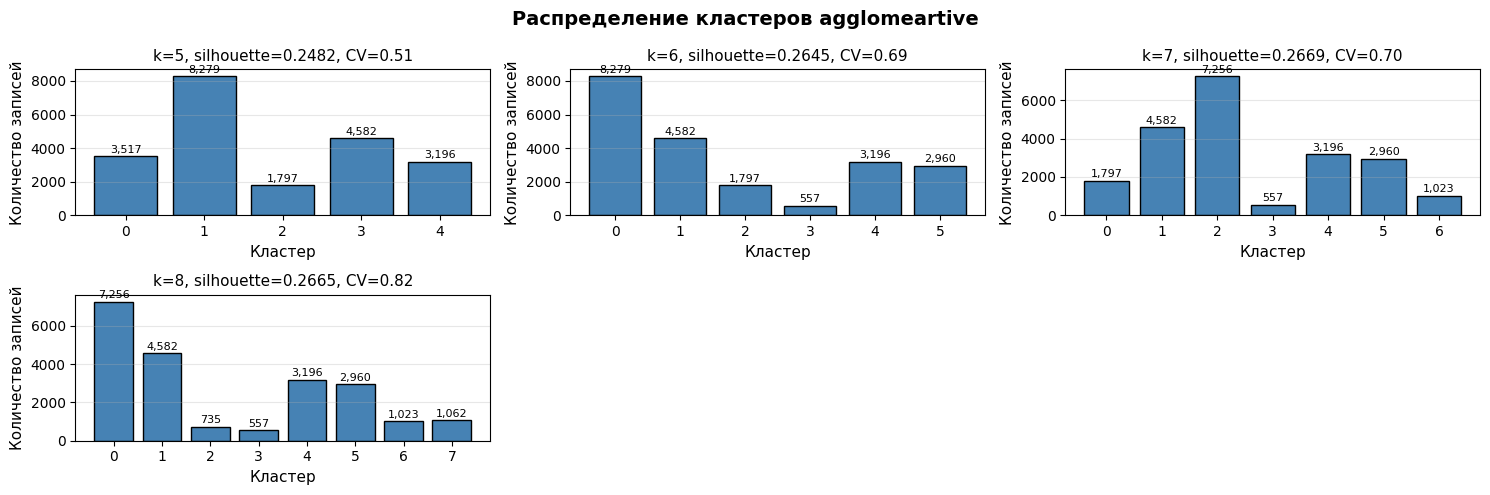

In [ ]:
plot_clusters_distribution(agglo_results[::3], model_name='agglomerative')

**Анализ:**

- **complete и average** — формально показывают высокий silhouette (0.43-0.51), но распределение катастрофически несбалансированно: один кластер поглощает 95-99% данных, остальные содержат единицы записей. **Причина:** эти методы ориентированы на компактность — объединение происходит только при высокой близости точек. Плотное ядро данных схлопывается в один кластер, а любые отклонения от типичного паттерна (редкие движения, переходные состояния) изолируются в карликовые кластеры. Высокий силуэт достигается за счет удаленности этих кластеров от гигантского — формально хорошо, содержательно бесполезно.

- **ward, k=7** — silhouette=0.2669 (максимальный среди ward). По сравнению с k=6 крупнейший кластер дробится на два. Силуэт вырос незначительно (+0.0024), ценой добавления карликового кластера (1,023).

- **ward, k=5** — коэффициент вариации 0.51 (против 0.69 при k=6 и 0.7 при k=7). Наиболее сбалансирован.

- **ward, k=6** — выделяет редкий паттерн (557 записей), скрытый при k=5. Silhouette выше, чем при k=5 (0.2645 vs 0.2482).

**Вывод:** для Agglomerative подходит только ward. Оптимальный выбор `k` зависит от цели: `k=5` — если важна максимальная сбалансированность (коэффициент вариации 0.51); k=6 — если допустимо выделение карликового кластера (557 записей) ради выявления редкого паттерна активности и чуть более высокого силуэта (0.2645 vs 0.2482). `k=7` не рекомендуется — добавляет второй карликовый кластер (1,023) при минимальном приросте силуэта (+0.0024).

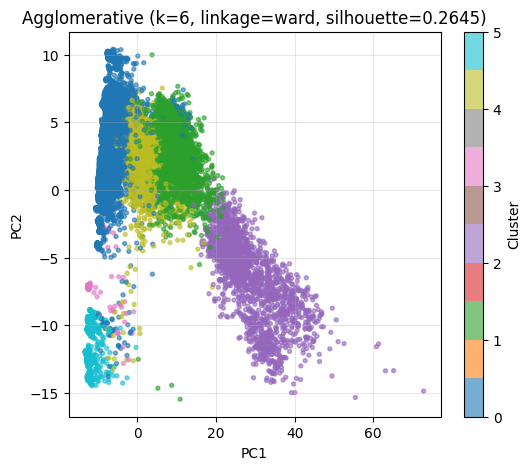

In [37]:
res_i = 3
plot_clusters_2d(
    X=X_pca,
    labels=agglo_results[res_i]['labels'],
    title=f"Agglomerative (k={agglo_results[res_i]['k']}, linkage={agglo_results[res_i]['linkage']}, silhouette={agglo_results[res_i]['silhouette']:.4f})"
)

### Общие выводы

**DBSCAN** не подходит для задачи: физическая активность формирует континуум с плавными переходами, тогда как DBSCAN требует четко разделимых кластеров. При малых eps данные дробятся на микро-кластеры, при больших — 95%+ сливаются в один гигантский кластер.

**Agglomerative:** только **ward** формирует интерпретируемую структуру. complete и average создают иллюзию высокого качества за счет экстремальной несбалансированности (один кластер поглощает 95-99% данных).

**KMeans** показал стабильный результат с оптимальным силуэтом при k=5, распределение образует естественный градиент интенсивности активности.

**Финальные модели для выгрузки на Kaggle**

Выбраны три модели, отражающие разные компромиссы между балансом кластеров и детализацией:

- KMeans, k=5 (silhouette=0.2548) — максимальный силуэт среди KMeans, сбалансированная иерархия кластеров

- Agglomerative (ward), k=5 (silhouette=0.2482) — наиболее сбалансированное распределение

- Agglomerative (ward), k=6 (silhouette=0.2645) — чуть выше качество, выделение редкого паттерна активности (557 записей)


### Формирование submission-файлов

Перед сохранением выполняется **обратная агрегация** — присвоение кластера каждой записи исходного датасета.

**Процесс:**
1. Каждой записи присваивается кластер того окна, в центре которого она находится. Вес уверенности убывает при удалении от центра.
2. Пропуски заполняются ближайшими соседями (forward + backward fill)
3. `rename_clusters_by_first_occurrence` перенумеровывает кластеры в порядке первого появления (1, 2, 3...)

In [38]:
def rename_clusters_by_first_occurrence(labels):
    # Создаем словарь для маппинга в порядке первого появления
    mapping = {}
    next_id = 1

    for label in labels:
        if label not in mapping and label != -1:  # Пропускаем -1
            mapping[label] = next_id
            next_id += 1

    # Применяем маппинг
    new_labels = np.array([mapping.get(label, -1) for label in labels])

    print("\nМАППИНГ КЛАСТЕРОВ (в порядке первого появления):")
    print("-" * 50)
    for old, new in mapping.items():
        print(f"  Старый кластер {old} → activityID {new}")

    return new_labels, mapping

# Используем исправленную функцию для заполнения пропусков
def assign_clusters_to_original_data_fixed(metadata_df, window_clusters, original_data):
    n_records = len(original_data)
    final_clusters = np.full(n_records, -1, dtype=int)
    best_confidence = np.zeros(n_records)

    # Шаг 1: Присваиваем кластеры на основе центров окон
    print("Шаг 1: Присвоение кластеров на основе центров окон...")
    assigned_count = 0

    for idx, row in metadata_df.iterrows():
        window_indices = row['window_indices']
        cluster = window_clusters[idx]

        window_len = len(window_indices)
        center = window_len // 2

        for position, record_idx in enumerate(window_indices):
            if record_idx < n_records:
                distance_to_center = abs(position - center)
                confidence = 1.0 / (distance_to_center + 1)

                if confidence > best_confidence[record_idx]:
                    best_confidence[record_idx] = confidence
                    final_clusters[record_idx] = cluster
                    assigned_count += 1

    print(f"   Присвоено: {assigned_count} записей")

    # Шаг 2: Заполняем пропуски ближайшими соседями
    print("Шаг 2: Заполнение пропусков ближайшими соседями...")

    # Первый проход: заполняем вперед
    current_cluster = -1
    for i in range(n_records):
        if final_clusters[i] != -1:
            current_cluster = final_clusters[i]
        elif current_cluster != -1:
            final_clusters[i] = current_cluster

    # Второй проход: заполняем назад (для начала, где не заполнено)
    current_cluster = -1
    for i in range(n_records - 1, -1, -1):
        if final_clusters[i] != -1:
            current_cluster = final_clusters[i]
        elif current_cluster != -1:
            final_clusters[i] = current_cluster

    # Шаг 3: Если все еще есть -1, используем первый встретившийся кластер
    unassigned = np.sum(final_clusters == -1)
    if unassigned > 0:
        print(f"   Осталось незаполненных: {unassigned}")
        # Находим первый не -1 кластер
        first_cluster = final_clusters[final_clusters != -1][0] if len(final_clusters[final_clusters != -1]) > 0 else 0
        final_clusters[final_clusters == -1] = first_cluster
        print(f"   Заполнены первым кластером: {first_cluster}")

    # Проверка
    final_unassigned = np.sum(final_clusters == -1)
    print(f"\nИтоговое количество записей без кластера: {final_unassigned}")

    return final_clusters


In [49]:
# best = agglo_results[5]
best = kmeans_results[1]

best_labels = best['labels']
#print(best['k'], best['linkage'], best['silhouette'])
print(best['k'],  best['silhouette'])

5 0.2548172187123133


In [50]:
# 1. восстановление кластеров на исходные данные
original_labels = assign_clusters_to_original_data_fixed(
    metadata_df=metadata,
    window_clusters=best_labels,
    original_data=data
)

# 2. переименование кластеров
final_labels, mapping = rename_clusters_by_first_occurrence(original_labels)

# 3. формируем submission
submission = pd.DataFrame({
    "Index": data.index,
    "activityID": final_labels
})

# 4. сохранение
submission.to_csv("submission_final.csv", index=False)

f"Файл сохранён: submission_final.csv"

Шаг 1: Присвоение кластеров на основе центров окон...
   Присвоено: 790831 записей
Шаг 2: Заполнение пропусков ближайшими соседями...

Итоговое количество записей без кластера: 0

МАППИНГ КЛАСТЕРОВ (в порядке первого появления):
--------------------------------------------------
  Старый кластер 3 → activityID 1
  Старый кластер 1 → activityID 2
  Старый кластер 4 → activityID 3
  Старый кластер 0 → activityID 4
  Старый кластер 2 → activityID 5


'Файл сохранён: submission_final.csv'

Несмотря на сопоставимое качество Agglomerative (Ward, k=5), итоговая модель выбрана по результатам Kaggle — KMeans с k=5 продемонстрировал лучший итоговый score.

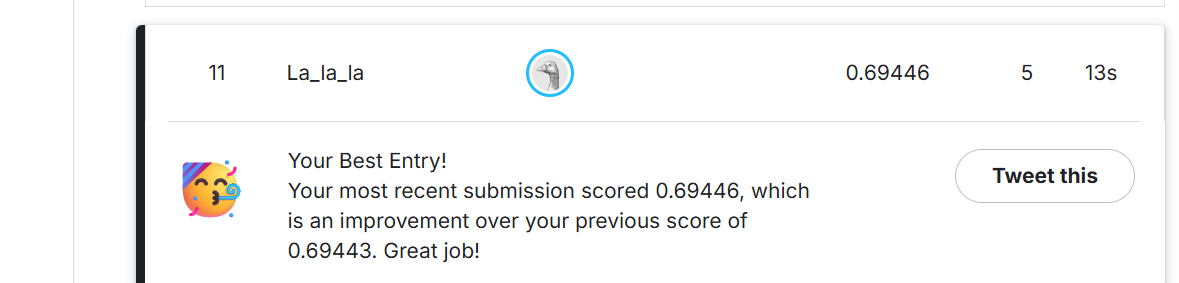